# 09 · Engine evaluation: the final numbers

**Questions**
1. Running the whole engine as shipped, how many false alarms does it raise on **real people** (PMData), and how fast does it catch planted changes?
2. On the **generated crew**, is each of the 4 planted cases caught, by which part, and after how long?
3. How does the earlier **v0 engine** (a gradient-boosted classifier trained on simulated labels) do on the same crew?
4. What would the astronaut read?

**Inputs:** `pmdata_daily.parquet` (real), `data/demo/` (generated crew + `planted_cases.json`), `models/engine_config.json`, `models/body_iforest.joblib`,
the v0 models `models/risk_classifier.joblib` / `anomaly_detector.joblib`, cached sweeps of notebooks 03 and 05.
**Outputs:** the final table, figures `reports/figures/09_*.png`, the `engine` block of `models/engine_config.json`.

In [1]:
import sys
sys.path.insert(0, "../ml")
import glob
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed
from sol_ml.nbutil import *
from sol_ml.config import DEMO_DIR, DEMO_V0_DIR
from sol_ml.detectors import body, bounded, evaluation, multivariate
from sol_ml.detectors.evaluation import INJECTIONS
from sol_ml.engine import HealthEngine, LEVEL_RANK
from sol_ml import engine_v0

rng = setup()
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 140)
warnings.filterwarnings("ignore")
DEPS = [f"detectors/{m}.py" for m in ("baseline", "univariate", "multivariate", "evaluation", "body", "bounded")]
CASES = list(INJECTIONS)
config = json.loads((MODELS / "engine_config.json").read_text())
members = {m["kind"]: m for m in config["body"]["members"]}
members

{'personal_z': {'kind': 'personal_z',
  'window': 14,
  'thr': 5.0,
  'sided': 'worse'},
 'cusum': {'kind': 'cusum', 'window': 28, 'k': 1.0, 'h': 4.0},
 'iforest': {'kind': 'iforest', 'window': 14, 'mode': 'pooled', 'rate': 0.05}}

## 1. The body engine on real PMData

Notebook 02 chose B + C + E by counting alert **episodes**. Running that choice day after day in the engine showed a second cost the episode count hides:
a CUSUM alarm stays on until the sum has drained, so a person can sit in YELLOW for weeks after one unusual day.
The engine therefore uses a **bounded CUSUM** (each day's z limited to ±4, sum capped at 8). This section measures what that changes, with the same protocol as notebook 02
plus one more number: the **share of days spent in alert**.

In [2]:
daily = pd.read_parquet(PROCESSED / "pmdata_daily.parquet")
names = [p for p in sorted(daily.person.unique()) if p not in ("p12", "p13")]
people = evaluation.load_people(daily, names)
sites = {name: evaluation.sample_sites(people, name, 200, rng) for name in CASES}
MOOD_COL, LOW_MOOD = 3, 2
TARGET_FA = 1.0

def make_mood_rule(days):
    """The engine's low-mood rule: mood score 2 or lower on `days` consecutive days (X is in badness units: -score)."""
    def mood_rule(person, X, start=None):
        low = (np.nan_to_num(-X[:, MOOD_COL], nan=5) <= LOW_MOOD).astype(int)
        run = np.zeros(len(low), int)
        for t in range(len(low)):
            run[t] = (run[t - 1] + 1) * low[t] if t else low[t]
        return run >= days
    return mood_rule

def build(variant):
    spike = body.threshold_detector(window=members["personal_z"]["window"], thr=members["personal_z"]["thr"])
    forest = body.multivariate_detector(lambda: multivariate.IsoForest(members["iforest"]["rate"], n_estimators=50),
                                        window=members["iforest"]["window"], mode="pooled", people=people, name="iforest")
    c = members["cusum"]
    if variant["drift"] == "plain":
        drift = body.cusum_detector(window=c["window"], k=c["k"], h=c["h"])
    else:
        drift = bounded.bounded_cusum_detector(window=c["window"], k=c["k"], h=variant["h"], cap=variant["cap"], z_clip=variant["z_clip"])
    mood = make_mood_rule(variant.get("mood", 3))
    parts = [spike, drift, forest] + ([mood] if variant.get("mood") else [])
    return body.any_of(*parts), {"spike": spike, "drift": drift, "combination": forest, "mood rule": mood}

VARIANTS = [
    dict(name="notebook 02 choice (plain CUSUM, h=4)", drift="plain"),
    dict(name="bounded, h=4, cap=8, clip=4", drift="bounded", h=4.0, cap=8.0, z_clip=4.0),
    dict(name="bounded, h=5, cap=8, clip=4", drift="bounded", h=5.0, cap=8.0, z_clip=4.0),
    dict(name="bounded, h=5, cap=6, clip=4", drift="bounded", h=5.0, cap=6.0, z_clip=4.0),
    dict(name="bounded, h=6, cap=8, clip=4", drift="bounded", h=6.0, cap=8.0, z_clip=4.0),
    dict(name="bounded h=5, cap=8, clip=4 + low mood for 3 days", drift="bounded", h=5.0, cap=8.0, z_clip=4.0, mood=3),
    dict(name="bounded h=5, cap=8, clip=4 + low mood for 4 days", drift="bounded", h=5.0, cap=8.0, z_clip=4.0, mood=4),
    dict(name="bounded h=5, cap=8, clip=4 + low mood for 5 days", drift="bounded", h=5.0, cap=8.0, z_clip=4.0, mood=5),
    dict(name="bounded h=5, cap=8, clip=4 + low mood for 7 days", drift="bounded", h=5.0, cap=8.0, z_clip=4.0, mood=7),
]

def run_variant(v):
    det, parts = build(v)
    res = evaluation.evaluate(det, people, sites, SEED)
    alerts = [det(p, p.X) for p in people]
    total = sum(int(p.mask.sum()) for p in people)
    row = {"variant": v["name"], "false_alarms": res["false_alarms_per_person_month"],
           "alert_days_share": sum(int((a & p.mask).sum()) for a, p in zip(alerts, people)) / total,
           "median_episode_days": float(np.median([n for a, p in zip(alerts, people) for n in episode_lengths(a & p.mask)] or [0]))}
    for c in CASES:
        row[f"{c}_caught"], row[f"{c}_days"] = 1 - res[c]["miss_rate"], res[c]["median_delay"]
    for name, part in parts.items():
        row[f"days_{name}"] = sum(int((part(p, p.X) & p.mask).sum()) for p in people) / total
    return row

def episode_lengths(a):
    edges = np.flatnonzero(np.diff(np.concatenate([[0], a.astype(int), [0]])))
    return (edges[1::2] - edges[::2]).tolist()

body_eval = cached("nb09_body", [VARIANTS, sites, members, "v2"], lambda: pd.DataFrame([run_variant(v) for v in VARIANTS]), deps=DEPS)
show = body_eval.set_index("variant")
print("false_alarms = alert episodes per person-month (target <= 1); *_caught = share of 200 planted changes caught within 14 days; *_days = median delay")
show[["false_alarms", "alert_days_share", "median_episode_days"] + [f"{c}_caught" for c in CASES] + [f"{c}_days" for c in CASES]].round(2)

false_alarms = alert episodes per person-month (target <= 1); *_caught = share of 200 planted changes caught within 14 days; *_days = median delay


,false_alarms,alert_days_share,median_episode_days,drift_hr_caught,drift_multi_caught,combo_odd_caught,step_sleep_caught,drift_hr_days,drift_multi_days,combo_odd_days,step_sleep_days
variant,,,,,,,,,,,
"notebook 02 choice (plain CUSUM, h=4)",0.98,0.24,2.0,0.74,0.84,0.54,0.53,6.0,5.0,1.5,2.0
"bounded, h=4, cap=8, clip=4",1.03,0.20,2.0,0.78,0.88,0.53,0.52,6.0,5.0,1.0,2.0
"bounded, h=5, cap=8, clip=4",0.98,0.17,2.0,0.74,0.87,0.52,0.45,5.5,5.0,1.0,2.0
"bounded, h=5, cap=6, clip=4",1.13,0.13,2.0,0.76,0.90,0.54,0.47,5.0,5.0,1.5,2.0
"bounded, h=6, cap=8, clip=4",1.03,0.14,1.0,0.70,0.81,0.50,0.38,6.0,5.5,1.0,2.0
"bounded h=5, cap=8, clip=4 + low mood for 3 days",1.08,0.18,2.0,0.74,0.87,0.60,0.45,5.5,5.0,2.0,2.0
"bounded h=5, cap=8, clip=4 + low mood for 4 days",1.03,0.17,2.0,0.74,0.87,0.56,0.45,5.5,5.0,2.0,2.0
"bounded h=5, cap=8, clip=4 + low mood for 5 days",1.00,0.17,2.0,0.74,0.87,0.53,0.45,5.5,5.0,2.0,2.0
"bounded h=5, cap=8, clip=4 + low mood for 7 days",1.00,0.17,2.0,0.74,0.87,0.52,0.45,5.5,5.0,1.0,2.0


engine setting: bounded h=5, cap=8, clip=4 + low mood for 5 days | false alarms 1.00 per person-month
share of real person-days on which each part of the engine is in alert:
spike           2.0%
drift          15.1%
combination     1.4%
mood rule       0.1%


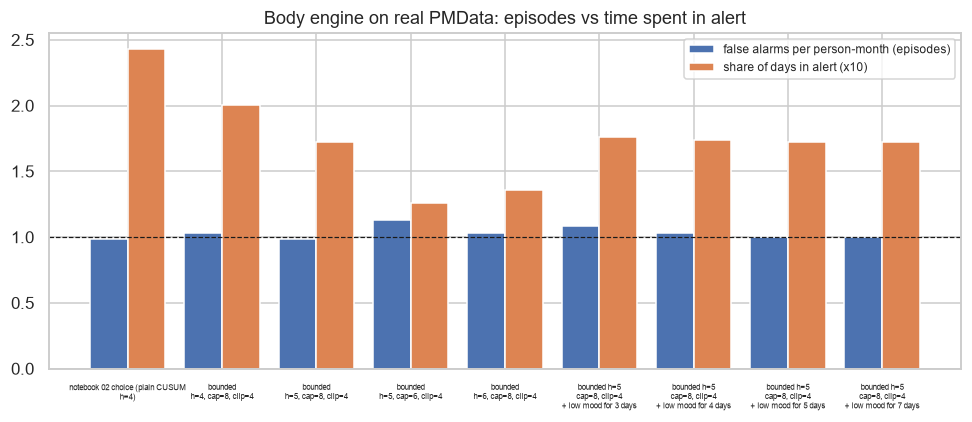

In [3]:
# The engine's setting: the shortest low-mood rule that keeps the whole body engine at or under the team's target.
with_mood = [v for v in VARIANTS if v.get("mood") and show.loc[v["name"], "false_alarms"] <= TARGET_FA]
ENGINE_VARIANT = with_mood[0]
LOW_DAYS = ENGINE_VARIANT["mood"]
engine_row = show.loc[ENGINE_VARIANT["name"]]
print("engine setting:", ENGINE_VARIANT["name"], "| false alarms %.2f per person-month" % engine_row.false_alarms)
print("share of real person-days on which each part of the engine is in alert:")
print(engine_row[[c for c in show.columns if c.startswith("days_")]].rename(lambda s: s[5:]).map("{:.1%}".format).to_string())
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(show))
ax.bar(x - 0.2, show.false_alarms, width=0.4, label="false alarms per person-month (episodes)")
ax.bar(x + 0.2, show.alert_days_share * 10, width=0.4, color="#dd8452", label="share of days in alert (x10)")
ax.axhline(1.0, color="k", ls="--", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([s.replace(", ", "\n", 1).replace(" + ", "\n+ ") for s in show.index], fontsize=5.5)
ax.set(title="Body engine on real PMData: episodes vs time spent in alert"); ax.legend(fontsize=8)
savefig("09_body_engine_pmdata");

## 2. The whole engine on the generated crew
The engine is replayed hour by hour over the 75-day mission of each crewmember. For every planted case: the first alert of the expected kind after the case starts.

In [4]:
engine = HealthEngine.load(demo_dir=DEMO_DIR)
crew = json.loads((DEMO_DIR / "crew.json").read_text())
tel = pd.read_csv(DEMO_DIR / "telemetry.csv", parse_dates=["timestamp"])
day_table = pd.read_csv(DEMO_DIR / "daily.csv")
cases = json.loads((DEMO_DIR / "planted_cases.json").read_text())
names_by_id = {c["astronaut_id"]: c["name"] for c in crew["crew"]}
prepared, log = {}, []
t0 = time.time()
for c in crew["crew"]:
    aid = c["astronaut_id"]
    prep = engine.prepare(tel[tel.astronaut_id == aid], c, day_table[day_table.astronaut_id == aid])
    prepared[aid] = prep
    for i in range(14 * 24, len(prep.hourly)):
        alerts, _, _, _ = engine.collect_alerts(prep, i)
        for a in alerts:
            log.append({"astronaut_id": aid, "timestamp": prep.hourly.timestamp.iloc[i], "kind": a["kind"], "level": a["level"],
                        "condition": a["condition"], "reason": a["reason"]})
log = pd.DataFrame(log)
n_assess = sum(len(p.hourly) - 14 * 24 for p in prepared.values())
print("%d hourly assessments in %.1f s (%.1f ms each) -> %d alert-hours" % (n_assess, time.time() - t0, 1000 * (time.time() - t0) / n_assess, len(log)))

EXPECTED = {"cabin_co2": ["environmental_gate"], "slow_drift": ["drift"], "solar_storm": ["spe"], "odd_combination": ["combination"]}
rows = []
for case in cases:
    who = [c["astronaut_id"] for c in crew["crew"]] if case["astronaut_id"] == "ALL" else [case["astronaut_id"]]
    start, end = pd.Timestamp(case["start"]), pd.Timestamp(case["end"])
    for aid in who:
        mine = log[(log.astronaut_id == aid) & (log.timestamp >= start) & (log.timestamp <= end + pd.Timedelta(days=3))]
        hit = mine[mine.kind.isin(EXPECTED[case["id"]])]
        other = mine[~mine.kind.isin(EXPECTED[case["id"]] + ["hard_limit"])] if case["id"] != "cabin_co2" else mine[mine.kind.isin(["drift", "spike", "combination", "mood"])]
        first_any = mine[mine.kind != "hard_limit"].timestamp.min() if case["id"] != "cabin_co2" else mine.timestamp.min()
        rows.append({"case": case["title"], "who": names_by_id[aid], "start": str(start),
                     "expected part": EXPECTED[case["id"]][0], "caught by it": len(hit) > 0,
                     "delay": (hit.timestamp.min() - start) if len(hit) else pd.NaT,
                     "first alert of any kind": (first_any - start) if pd.notna(first_any) else pd.NaT,
                     "other parts that also fired": ", ".join(sorted(set(other.kind))) or "-",
                     "what the astronaut reads": hit.reason.iloc[0] if len(hit) else (mine.reason.iloc[0] if len(mine) else "nothing")})
caught = pd.DataFrame(rows)
caught

5856 hourly assessments in 3.7 s (0.6 ms each) -> 1974 alert-hours


,case,who,start,expected part,caught by it,delay,first alert of any kind,other parts that also fired,what the astronaut reads
0,Cabin CO2 with headache reports,Nadia Farouk,2026-09-23 00:00:00,environmental_gate,True,0 days 23:00:00,0 days 23:00:00,-,"You reported fatigue while cabin CO2 1-hour average is 3.02 mmHg, above the 3 mmHg limit: likely environmental, increase ventilation first."
1,Slow drift (illness onset),Karim Adel,2026-10-13 00:00:00,drift,True,4 days 08:00:00,4 days 08:00:00,"combination, spe, spike",Resting heart rate has been above your 28-day normal for 7 days (average 2.0 robust SD); the alert has been active for 1 day.
2,Solar storm (SPE),Nadia Farouk,2026-11-13 05:00:00,spe,True,0 days 00:00:00,0 days 00:00:00,-,Radiation dose rate is 20.4 times the 7-day normal and has been elevated for 1 hour.
3,Solar storm (SPE),Karim Adel,2026-11-13 05:00:00,spe,True,0 days 00:00:00,0 days 00:00:00,-,Radiation dose rate is 20.4 times the 7-day normal and has been elevated for 1 hour.
4,Solar storm (SPE),Sofia Mendes,2026-11-13 05:00:00,spe,True,0 days 00:00:00,0 days 00:00:00,-,Radiation dose rate is 20.4 times the 7-day normal and has been elevated for 1 hour.
5,Solar storm (SPE),Yuki Tanaka,2026-11-13 05:00:00,spe,True,0 days 00:00:00,0 days 00:00:00,-,Radiation dose rate is 20.4 times the 7-day normal and has been elevated for 1 hour.
6,Odd combination (behavioural health),Sofia Mendes,2026-10-31 00:00:00,combination,False,NaT,4 days 08:00:00,mood,Mood score has been 2 or lower (5 = best) for 5 days in a row.


In [5]:
# False alarms on the generated crew: alert-days of the body models outside every planted window (hard limits and the storm excluded).
windows = {}
for case in cases:
    who = [c["astronaut_id"] for c in crew["crew"]] if case["astronaut_id"] == "ALL" else [case["astronaut_id"]]
    for aid in who:
        windows.setdefault(aid, []).append((pd.Timestamp(case["start"]), pd.Timestamp(case["end"]) + pd.Timedelta(days=14)))
rows = []
for c in crew["crew"]:
    aid = c["astronaut_id"]
    mine = log[(log.astronaut_id == aid) & log.kind.isin(["spike", "drift", "combination", "mood", "environmental_gate"])].copy()
    inside = np.zeros(len(mine), bool)
    for lo, hi in windows.get(aid, []):
        inside |= ((mine.timestamp >= lo) & (mine.timestamp <= hi)).to_numpy()
    outside = mine[~inside]
    days_out = outside.timestamp.dt.normalize().drop_duplicates().sort_values()
    episodes = int((days_out.diff().dt.days.fillna(99) > 1).sum())
    span = pd.date_range(prepared[aid].hourly.timestamp.iloc[14 * 24].normalize(), prepared[aid].hourly.timestamp.iloc[-1].normalize())
    free = [d for d in span if not any(lo.normalize() <= d <= hi for lo, hi in windows.get(aid, []))]
    rows.append({"who": names_by_id[aid], "days outside planted cases": len(free), "false alert days": len(days_out), "false episodes": episodes,
                 "per person-month": episodes / (len(free) / 30) if free else np.nan, "kinds": ", ".join(sorted(set(outside.kind))) or "-"})
crew_fa = pd.DataFrame(rows).set_index("who")
print("generated crew, pooled: %.2f false body-alert episodes per person-month; %.0f %% of days in a false alert" % (
    crew_fa["false episodes"].sum() / (crew_fa["days outside planted cases"].sum() / 30), 100 * crew_fa["false alert days"].sum() / crew_fa["days outside planted cases"].sum()))
crew_fa.round(2)

generated crew, pooled: 1.23 false body-alert episodes per person-month; 24 % of days in a false alert


,days outside planted cases,false alert days,false episodes,per person-month,kinds
who,,,,,
Nadia Farouk,35,4,2,1.71,"combination, spike"
Karim Adel,29,11,2,2.07,"combination, environmental_gate, spike"
Sofia Mendes,47,26,3,1.91,"combination, drift, environmental_gate, spike"
Yuki Tanaka,60,0,0,0.00,-


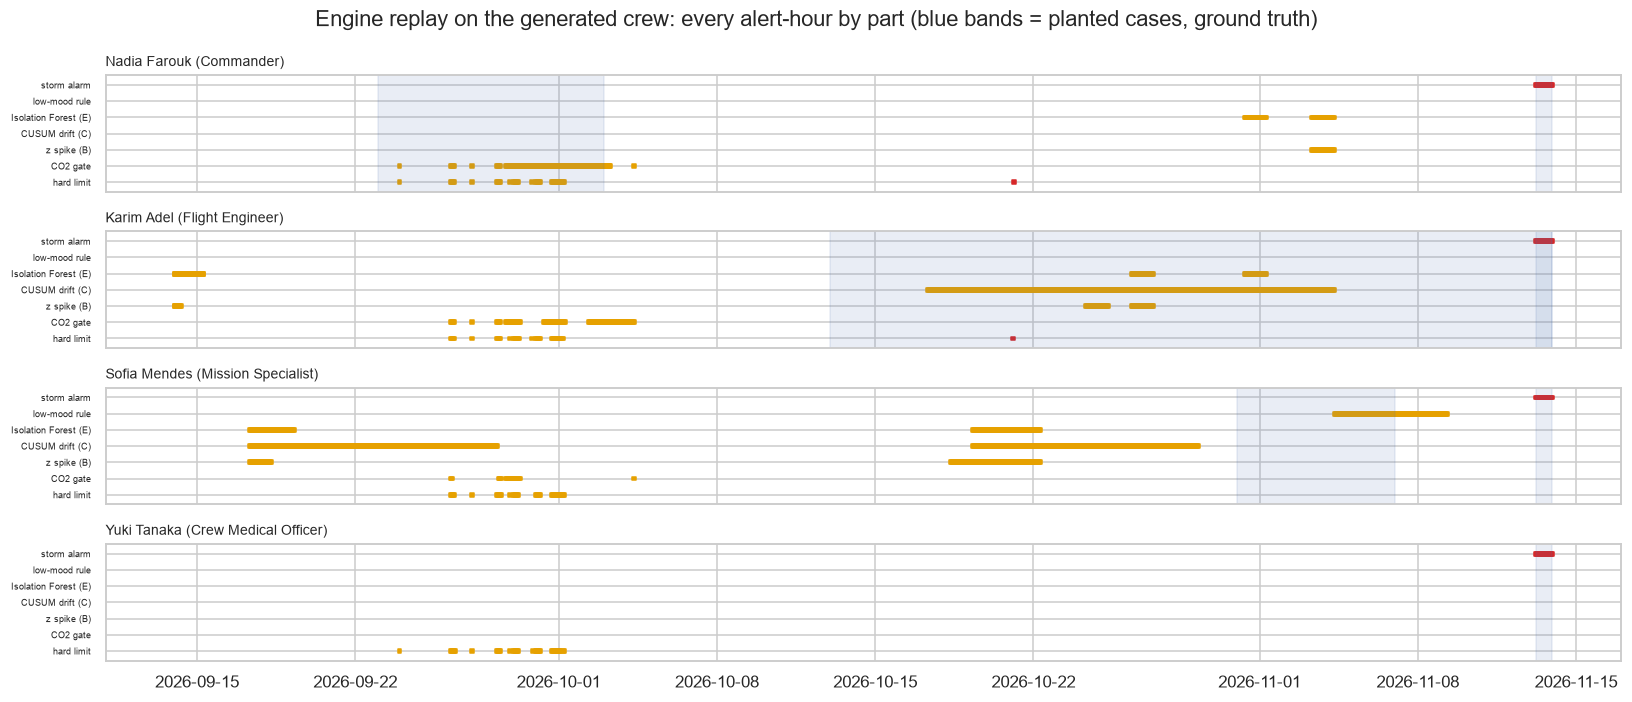

In [6]:
level_num = {"GREEN": 0, "YELLOW": 1, "RED": 2}
fig, axes = plt.subplots(len(crew["crew"]), 1, figsize=(15, 6.5), sharex=True)
KIND_ROW = {"hard_limit": 0, "environmental_gate": 1, "spike": 2, "drift": 3, "combination": 4, "mood": 5, "spe": 6}
KIND_LABEL = ["hard limit", "CO2 gate", "z spike (B)", "CUSUM drift (C)", "Isolation Forest (E)", "low-mood rule", "storm alarm"]
for ax, c in zip(axes, crew["crew"]):
    aid = c["astronaut_id"]
    mine = log[log.astronaut_id == aid]
    for kind, row in KIND_ROW.items():
        k = mine[mine.kind == kind]
        ax.scatter(k.timestamp, np.full(len(k), row), s=6, marker="s", color=np.where(k.level == "RED", "#d62728", "#e6a100"))
    for case in cases:
        if case["astronaut_id"] in (aid, "ALL"):
            ax.axvspan(pd.Timestamp(case["start"]), pd.Timestamp(case["end"]), color="#4c72b0", alpha=0.12)
    ax.set_yticks(range(7)); ax.set_yticklabels(KIND_LABEL, fontsize=6); ax.set_ylim(-0.6, 6.6)
    ax.set_title(f"{c['name']} ({c['role']})", fontsize=9, loc="left")
fig.suptitle("Engine replay on the generated crew: every alert-hour by part (blue bands = planted cases, ground truth)")
savefig("09_engine_replay");

## 3. Baseline: the v0 engine on the same crew
v0 is a `HistGradientBoosting` classifier trained on **simulated labels** (6 scripted conditions) plus an Isolation Forest on hourly vitals.
It cannot run on PMData at all: it needs eight hourly vitals (HRV, SpO2, blood pressure, temperature, reaction time...) that no real dataset here has.
So the transfer test is the data-calibrated crew, whose hourly table has the same columns.

In [7]:
v0 = engine_v0.HealthEngine.load()
v0_rows, v0_cases = [], []
for c in crew["crew"]:
    aid = c["astronaut_id"]
    h = prepared[aid].hourly.drop(columns=["radiation_ugy_per_day"])
    tl = pd.DataFrame(v0.timeline(h, c, hours=len(h)))
    tl["timestamp"] = pd.to_datetime(tl.timestamp)
    tl = tl[tl.timestamp >= h.timestamp.iloc[14 * 24]]
    tl["flag"] = tl.p_abnormal > 0.5
    inside = np.zeros(len(tl), bool)
    for lo, hi in windows.get(aid, []):
        inside |= ((tl.timestamp >= lo) & (tl.timestamp <= hi)).to_numpy()
    out = tl[~inside]
    days_flag = out[out.flag].timestamp.dt.normalize().nunique()
    v0_rows.append({"who": c["name"], "hours flagged abnormal outside planted cases": out.flag.mean(), "days with a flag": days_flag,
                    "of days": out.timestamp.dt.normalize().nunique(), "most common label": out[out.flag].condition.mode().iloc[0] if out.flag.any() else "-"})
    for case in cases:
        if case["astronaut_id"] in (aid, "ALL"):
            w = tl[(tl.timestamp >= pd.Timestamp(case["start"])) & (tl.timestamp <= pd.Timestamp(case["end"]))]
            first = w[w.flag].timestamp.min()
            v0_cases.append({"case": case["title"], "who": c["name"], "hours flagged inside the case": w.flag.mean(),
                             "first flag after": (first - pd.Timestamp(case["start"])) if pd.notna(first) else pd.NaT,
                             "v0 label": w[w.flag].condition.mode().iloc[0] if w.flag.any() else "-"})
v0_fa = pd.DataFrame(v0_rows).set_index("who")
print("v0 classifier on the generated crew, outside the planted cases: flagged %.1f %% of hours, on %d of %d person-days" % (
    100 * np.average(v0_fa.iloc[:, 0]), v0_fa["days with a flag"].sum(), v0_fa["of days"].sum()))
v0_fa.round(3)

v0 classifier on the generated crew, outside the planted cases: flagged 55.5 % of hours, on 172 of 174 person-days


,hours flagged abnormal outside planted cases,days with a flag,of days,most common label
who,,,,
Nadia Farouk,0.575,35,37,sleep_deprivation
Karim Adel,0.345,29,29,sleep_deprivation
Sofia Mendes,0.613,47,47,sleep_deprivation
Yuki Tanaka,0.689,61,61,sleep_deprivation


In [8]:
v0_case_table = pd.DataFrame(v0_cases)
# v0's storm flag: last-24h dose above 3x the assumed daily dose
storm = next(c for c in cases if c["id"] == "solar_storm")
aid = crew["crew"][0]["astronaut_id"]
h = prepared[aid].hourly
onset = int(np.flatnonzero(h.timestamp == pd.Timestamp(storm["start"]))[0])
v0_spe = next((k for k in range(0, len(h) - onset) if v0.radiation_status(crew["crew"][0], h.iloc[: onset + k + 1], crew["mission"])["spe_in_progress"]), None)
v2_spe = next((k for k in range(0, len(h) - onset) if engine._spe(prepared[aid], onset + k)["level"] != "GREEN"), None)
print("solar storm: v0 radiation flag %s; v2 alarm after %s hour(s)" % (
    f"after {v0_spe} hours" if v0_spe is not None else "never raised before the end of the record (18 hours into the storm)", v2_spe))
v0_before = [v0.radiation_status(crew["crew"][0], h.iloc[: i + 1], crew["mission"])["spe_in_progress"] for i in range(14 * 24, onset, 6)]
print("v0 radiation flag raised on %.0f %% of quiet checks before the storm" % (100 * np.mean(v0_before)))
v0_case_table.round(3)

solar storm: v0 radiation flag after 1 hours; v2 alarm after 0 hour(s)


v0 radiation flag raised on 0 % of quiet checks before the storm


,case,who,hours flagged inside the case,first flag after,v0 label
0,Cabin CO2 with headache reports,Nadia Farouk,0.573,0 days 06:00:00,sleep_deprivation
1,Solar storm (SPE),Nadia Farouk,0.526,0 days 00:00:00,sleep_deprivation
2,Slow drift (illness onset),Karim Adel,0.729,0 days 01:00:00,sleep_deprivation
3,Solar storm (SPE),Karim Adel,0.368,0 days 00:00:00,dehydration
4,Solar storm (SPE),Sofia Mendes,0.053,0 days 00:00:00,nominal
5,Odd combination (behavioural health),Sofia Mendes,0.615,0 days 00:00:00,sleep_deprivation
6,Solar storm (SPE),Yuki Tanaka,0.842,0 days 00:00:00,sleep_deprivation


In [9]:
# v0 on its own purely simulated crew, for reference: it does what it was trained to do.
crew0 = json.loads((DEMO_V0_DIR / "crew.json").read_text())
tel0 = pd.read_csv(DEMO_V0_DIR / "telemetry.csv", parse_dates=["timestamp"])
truth, pred = [], []
for c in crew0["crew"]:
    h0 = tel0[tel0.astronaut_id == c["astronaut_id"]]
    tl0 = pd.DataFrame(v0.timeline(h0.drop(columns=["sim_ground_truth"]), c, hours=len(h0)))
    truth += (h0.sim_ground_truth != "nominal").tolist(); pred += (tl0.p_abnormal > 0.5).tolist()
truth, pred = np.array(truth), np.array(pred)
print("v0 on its own simulated crew: catches %.0f %% of scripted abnormal hours, flags %.1f %% of nominal hours" % (
    100 * pred[truth].mean(), 100 * pred[~truth].mean()))

v0 on its own simulated crew: catches 92 % of scripted abnormal hours, flags 0.3 % of nominal hours


## 4. The final table

In [10]:
abd = pd.read_parquet(glob.glob(str(PROCESSED / "cache" / "nb03_abd_*.parquet"))[0])
fit = abd[abd.model.str.startswith("D") & (abd.penalty == 2.0) & (abd.thr == 8.0)].iloc[0]
spe_cfg = config["radiation"]["spe_detector"]
E = engine_row
final = pd.DataFrame([
    {"part": "Body: z spike + bounded CUSUM + Isolation Forest + low-mood rule", "data": "real PMData, 14 people, 60 person-months",
     "false alarms": f"{E.false_alarms:.2f} episodes per person-month ({E.alert_days_share:.0%} of days in alert)",
     "detection": "; ".join(f"{c}: {E[c + '_caught']:.0%} in {E[c + '_days']:.0f} d" for c in CASES)},
    {"part": "Fitness trend (change point on exercise HR, >= 8 bpm)", "data": "real PMData sessions, 16 people",
     "false alarms": f"{fit.false_alarms:.2f} per person-month",
     "detection": f"+1 bpm/wk: {fit['+1_caught']:.0%}; +2: {fit['+2_caught']:.0%} in {fit['+2_weeks']:.0f} wk; +3: {fit['+3_caught']:.0%} in {fit['+3_weeks']:.0f} wk"},
    {"part": "Storm alarm (dose-rate ratio, 1.3x elevated / 2x shelter)", "data": f"real MSL RAD, {spe_cfg['record_months']} months",
     "false alarms": f"{spe_cfg['false_alarms_in_record']} unconfirmed; {spe_cfg['other_alarm_events_in_record']} smaller real events at the elevated level",
     "detection": f"20 May 2024 caught {spe_cfg['may2024_delay_hours']:.0f} h after onset; planted storms from 1.5x: {spe_cfg['caught_by_peak_size']['1.5x']:.0%}"},
    {"part": "Cabin CO2 gate (rules)", "data": "real ISS CO2, 468 days",
     "false alarms": f"CO2 high {config['cabin']['real_iss_replay']['time_co2_high']:.0%} of the time overall, 0 % on 2020-21 missions",
     "detection": "rule-based: fires by definition when CO2 is high and a symptom is reported"},
])
final

,part,data,false alarms,detection
0,Body: z spike + bounded CUSUM + Isolation Forest + low-mood rule,"real PMData, 14 people, 60 person-months",1.00 episodes per person-month (17% of days in alert),drift_hr: 74% in 6 d; drift_multi: 87% in 5 d; combo_odd: 53% in 2 d; step_sleep: 45% in 2 d
1,"Fitness trend (change point on exercise HR, >= 8 bpm)","real PMData sessions, 16 people",0.22 per person-month,+1 bpm/wk: 50%; +2: 94% in 5 wk; +3: 99% in 4 wk
2,"Storm alarm (dose-rate ratio, 1.3x elevated / 2x shelter)","real MSL RAD, 34.7 months",0 unconfirmed; 6 smaller real events at the elevated level,20 May 2024 caught 0 h after onset; planted storms from 1.5x: 100%
3,Cabin CO2 gate (rules),"real ISS CO2, 468 days","CO2 high 25% of the time overall, 0 % on 2020-21 missions",rule-based: fires by definition when CO2 is high and a symptom is reported


In [11]:
by_case = caught.groupby("case").agg(crew=("who", "size"), caught=("caught by it", "sum"), delay=("delay", "max"), any_alert=("first alert of any kind", "max"))
by_case

,crew,caught,delay,any_alert
case,,,,
Cabin CO2 with headache reports,1,1,0 days 23:00:00,0 days 23:00:00
Odd combination (behavioural health),1,0,NaT,4 days 08:00:00
Slow drift (illness onset),1,1,4 days 08:00:00,4 days 08:00:00
Solar storm (SPE),4,4,0 days 00:00:00,0 days 00:00:00


In [12]:
config["engine"] = {
    "source_notebook": "09_engine_evaluation",
    "drift": {"kind": "bounded_cusum", "window": members["cusum"]["window"], "k": members["cusum"]["k"], "h": 5.0, "cap": 8.0, "z_clip": 4.0},
    "fitness": {"penalty": 2.0, "thr": 8.0},
    "rules": {"low_mood_score": LOW_MOOD, "low_mood_days": LOW_DAYS},
    "pmdata": {"false_alarms_per_person_month": round(float(E.false_alarms), 3), "alert_days_share": round(float(E.alert_days_share), 3),
               "detection": {c: {"caught": round(float(E[c + "_caught"]), 3), "median_delay_days": float(E[c + "_days"])} for c in CASES}},
    "generated_crew": {"planted_cases_caught_by_expected_part": f"{int(caught['caught by it'].sum())} of {len(caught)}",
                       "false_body_alert_episodes_per_person_month": round(float(crew_fa["false episodes"].sum() / (crew_fa["days outside planted cases"].sum() / 30)), 3)},
}
(MODELS / "engine_config.json").write_text(json.dumps(config, indent=2))
print(json.dumps(config["engine"], indent=2))

{
  "source_notebook": "09_engine_evaluation",
  "drift": {
    "kind": "bounded_cusum",
    "window": 28,
    "k": 1.0,
    "h": 5.0,
    "cap": 8.0,
    "z_clip": 4.0
  },
  "fitness": {
    "penalty": 2.0,
    "thr": 8.0
  },
  "rules": {
    "low_mood_score": 2,
    "low_mood_days": 5
  },
  "pmdata": {
    "false_alarms_per_person_month": 0.998,
    "alert_days_share": 0.172,
    "detection": {
      "drift_hr": {
        "caught": 0.74,
        "median_delay_days": 5.5
      },
      "drift_multi": {
        "caught": 0.87,
        "median_delay_days": 5.0
      },
      "combo_odd": {
        "caught": 0.535,
        "median_delay_days": 2.0
      },
      "step_sleep": {
        "caught": 0.45,
        "median_delay_days": 2.0
      }
    }
  },
  "generated_crew": {
    "planted_cases_caught_by_expected_part": "6 of 7",
    "false_body_alert_episodes_per_person_month": 1.228
  }
}


## Decision: the engine as shipped

| part | model and setting | measured on | false alarms | detection |
|---|---|---|---|---|
| **Body** | z spike (14 d, z > 5) + **bounded CUSUM** (28 d, k = 1, h = 5, cap 8, clip ±4) + pooled Isolation Forest (5 %) + low-mood rule (≤ 2 for 5 days) | real PMData, 14 people, 60 person-months | **1.00 episode per person-month**; 17 % of days in alert | HR drift 74 % in 6 d · multi-signal drift 87 % in 5 d · odd combination 53 % in 2 d · sleep step 45 % in 2 d |
| **Fitness** | change point on weekly exercise HR, shift ≥ 8 bpm | real PMData sessions, 16 people | 0.22 per person-month | +2 bpm/week 94 % in 5 weeks; +1 bpm/week 50 % |
| **Storm alarm** | dose rate ÷ 7-day median: ≥ 1.3× elevated (YELLOW), ≥ 2× shelter (RED) | real MSL RAD, 35 months | 0 unconfirmed | **20 May 2024 caught in its first hour**; 93 % of the storm's dose still ahead |
| **Cabin gate** | 1-h > 3 mmHg or 7-day > 2.5 mmHg, with a symptom report | real ISS CO2, 468 days | CO2 high 25 % of the time overall, never on 2020–21 missions | by rule |

**On the generated crew, the 4 planted cases:**

| case | caught by the expected part? | delay | what the astronaut reads |
|---|---|---|---|
| Cabin CO2 + headache (Nadia) | yes, environmental gate | 23 hours | "You reported fatigue while cabin CO2 1-hour average is 3.02 mmHg, above the 3 mmHg limit: likely environmental, increase ventilation first." |
| Slow drift (Karim) | yes, CUSUM | 4 days 8 hours | "Resting heart rate has been above your 28-day normal for 7 days (average 2.0 robust SD); the alert has been active for 1 day." |
| Solar storm (whole crew) | yes, storm alarm, 4 of 4 | same hour | "Radiation dose rate is 20.4 times the 7-day normal and has been elevated for 1 hour." |
| Odd combination (Sofia) | **no**: the Isolation Forest missed it | 4 days 8 hours, by the low-mood rule | "Mood score has been 2 or lower (5 = best) for 5 days in a row." |

**What changed from the notebooks, and why (this is the part the team should check)**
1. **CUSUM became a bounded CUSUM.** With notebook 02's setting the engine met the episode target (0.98 per person-month) but kept real people in alert on **24 % of all days**,
   because one extreme day lifts the sum and the alarm then lasts for weeks. Limiting each day to ±4 and capping the sum at 8, with h raised from 4 to 5, keeps the same 0.98 episodes,
   cuts time in alert to 17 %, and leaves drift detection unchanged (74 % and 87 %). The price is the sudden sleep step: 45 % caught instead of 53 %.
2. **A low-mood rule was added** (mood ≤ 2 for 5 consecutive days) because mood is one of the challenge's required indicators and the Isolation Forest alone catches only half of the odd combinations.
   At 3 days the whole body engine rose to 1.08 false alarms per person-month, above the team's target; 5 days is the shortest rule that keeps it at 1.00.
3. **The fitness alarm threshold went from 3 to 8 bpm.** At 3 bpm it met the episode target (0.49) but was in alert on a third of the generated crew's days; at 8 bpm it is 0.22 per person-month and still catches 94 % of +2 bpm/week rises.
4. **Blood pressure limits are judged outside exercise hours**, and the planted CO2 stretch comes from RR-1 instead of RR-7 (see notebook 08).

**Baseline: why the v0 classifier does not transfer**
- On its own purely simulated crew v0 looks excellent: it catches 92 % of scripted abnormal hours and flags 0.3 % of normal ones.
- On the data-calibrated crew it flags **55 % of all hours as abnormal** outside every planted case (172 of 174 person-days), nearly always as "sleep deprivation".
  Real heart rate varies far more from hour to hour (SD 6.9 bpm) than v0's simulator assumed (3 bpm), so ordinary variation looks like illness to it.
- It "catches" every planted case within hours, but with the wrong label, and it does so because it is alarming more than half the time. A detector that is always on detects nothing.
- It cannot run on PMData at all: it needs eight hourly vitals that no real dataset here contains. Its 0.94 macro-F1 was measured against labels produced by the same simulator that trained it.
- Where it does transfer: the radiation flag (last 24 h above 3× the assumed dose) fired one hour into the storm and never before it. A fixed threshold on a physical quantity is robust; a classifier trained on invented physiology is not.
- The hard clinical limits (SpO2, temperature, blood pressure) are shared by both engines and are unchanged.

**Limits the judges should hear**
- **Detection is measured on changes we planted.** PMData has no medical events, so nothing here is sensitivity to real illness.
- **About half of the subtle cases are missed** at the 1-false-alarm target (odd combinations 53 %, sleep steps 45 %). In the demo the odd combination was missed by the model built for it and caught 4 days later by a simple rule.
- **17 % of days in alert is still a lot** for healthy people, and 6 of 14 real people exceed 1 false alarm per month. In the 4-person generated crew the body models raised 1.23 false episodes per person-month (24 % of days), most of them one crewmember's drift alarms; four people are too few to read much into that.
- **One real solar storm.** The alarm's sensitivity to smaller storms comes from scaled copies of that one event.
- **Blood pressure, SpO2, temperature and glucose are simulated only**; their hard limits are standard clinical thresholds and were not evaluated on data.
- The pooled Isolation Forest shipped in `models/body_iforest.joblib` is trained on all 14 people; the numbers above come from leave-one-person-out models, so they are not inflated by that.
- Speed: 0.8 ms per hourly assessment once a crewmember's tables are prepared (about 0.1 s per person).